Which visual do you think is the most appropriate based on the data? Make a graph of the data (based on your choice of tooling) and share your visualization in class.


In [3]:
import pandas as pd
df = pd.read_excel("Waiting_times.xlsx")
df.head()

,Year,Month,Min,Avg waiting time,Max
0,2023,Sep,9,18,27
1,2023,Oct,6,12,17
2,2023,Nov,7,13,17
3,2023,Dec,12,18,26
4,2024,Jan,12,17,24


    Year Month  Min  Avg waiting time  Max
0   2023   Sep    9                18   27
1   2023   Oct    6                12   17
2   2023   Nov    7                13   17
3   2023   Dec   12                18   26
4   2024   Jan   12                17   24
5   2024   Feb    7                13   20
6   2024   Mar    7                12   18
7   2024   Apr    9                14   21
8   2024   May    8                13   21
9   2024   Jun   12                18   28
10  2024   Jul   13                19   26
11  2024   Aug   17                24   36
12  2024   Sep   14                21   32


KeyError: 'Average'

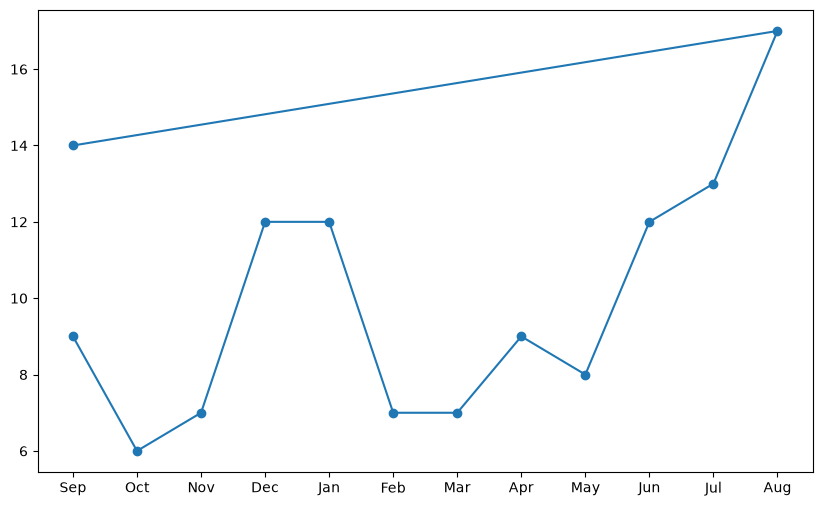

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Excel file
df = pd.read_excel("Waiting_times.xlsx")

# Check the data
print(df)

# Create the line graph
plt.figure(figsize=(10, 6))

plt.plot(df["Month"], df["Min"], marker="o", label="Minimum")
plt.plot(df["Month"], df["Average"], marker="o", label="Average")
plt.plot(df["Month"], df["Max"], marker="o", label="Maximum")

# Add title and labels
plt.title("Waiting Times by Month")
plt.xlabel("Month")
plt.ylabel("Waiting Time")

# Improve readability
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Display the graph
plt.show()

Index(['Year', 'Month', 'Min', 'Avg waiting time', 'Max'], dtype='str')
    Year Month  Min  Avg waiting time  Max
0   2023   Sep    9                18   27
1   2023   Oct    6                12   17
2   2023   Nov    7                13   17
3   2023   Dec   12                18   26
4   2024   Jan   12                17   24
5   2024   Feb    7                13   20
6   2024   Mar    7                12   18
7   2024   Apr    9                14   21
8   2024   May    8                13   21
9   2024   Jun   12                18   28
10  2024   Jul   13                19   26
11  2024   Aug   17                24   36
12  2024   Sep   14                21   32


KeyError: 'Average'

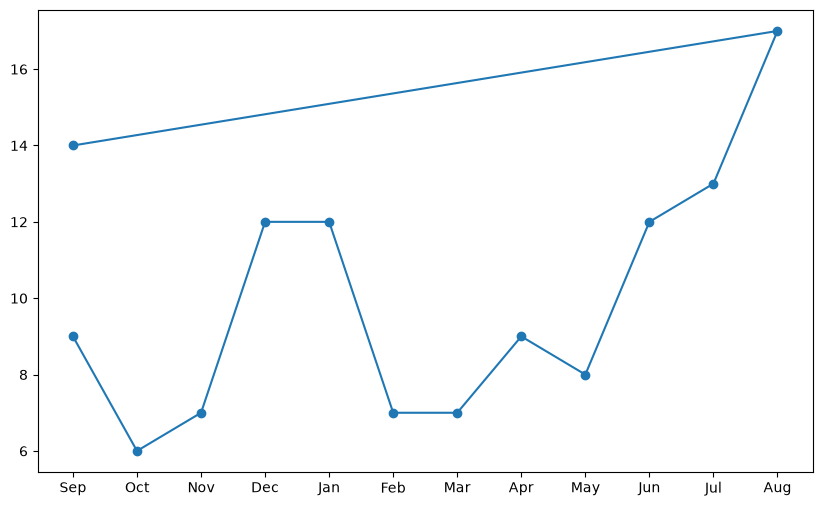

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Waiting_times.xlsx")

# Kijk eerst hoe de kolommen precies heten
print(df.columns)
print(df)

plt.figure(figsize=(10, 6))

plt.plot(df["Month"], df["Min"], marker="o", label="Minimum")
plt.plot(df["Month"], df["Average"], marker="o", label="Average")
plt.plot(df["Month"], df["Max"], marker="o", label="Maximum")

plt.title("Waiting Times by Month")
plt.xlabel("Month")
plt.ylabel("Waiting Time")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

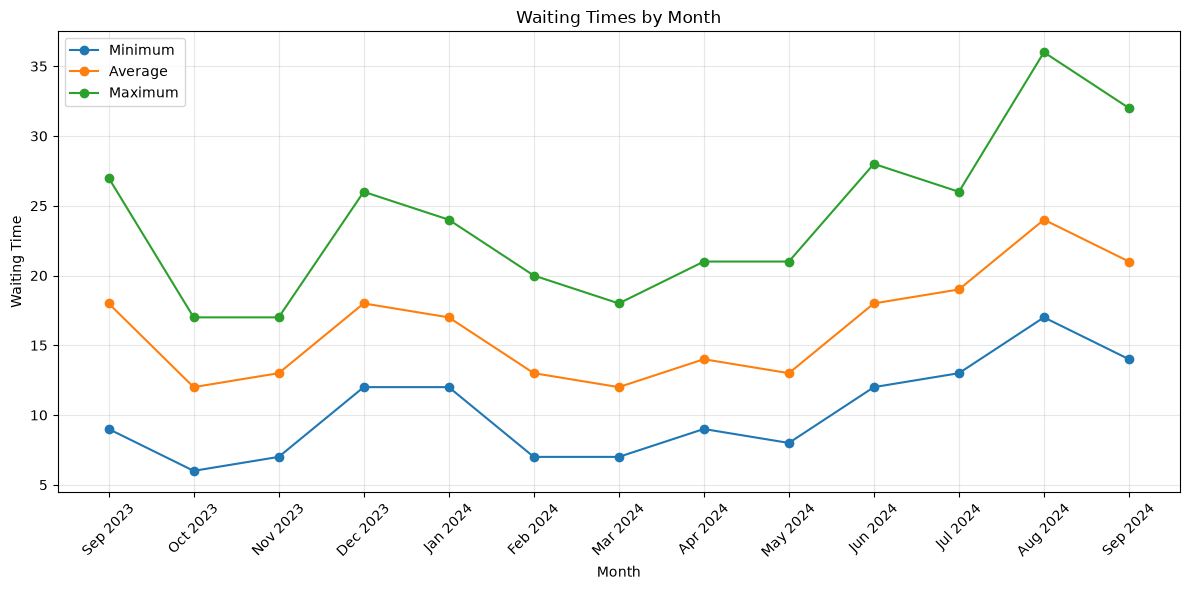

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Excelbestand inlezen
df = pd.read_excel("Waiting_times.xlsx")

# Jaar en maand combineren
df["Date"] = df["Month"] + " " + df["Year"].astype(str)

# Grafiek maken
plt.figure(figsize=(12, 6))

plt.plot(df["Date"], df["Min"],
         marker="o", label="Minimum")

plt.plot(df["Date"], df["Avg waiting time"],
         marker="o", label="Average")

plt.plot(df["Date"], df["Max"],
         marker="o", label="Maximum")

# Titel en assen
plt.title("Waiting Times by Month")
plt.xlabel("Month")
plt.ylabel("Waiting Time")

# Opmaak
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Grafiek tonen
plt.show()

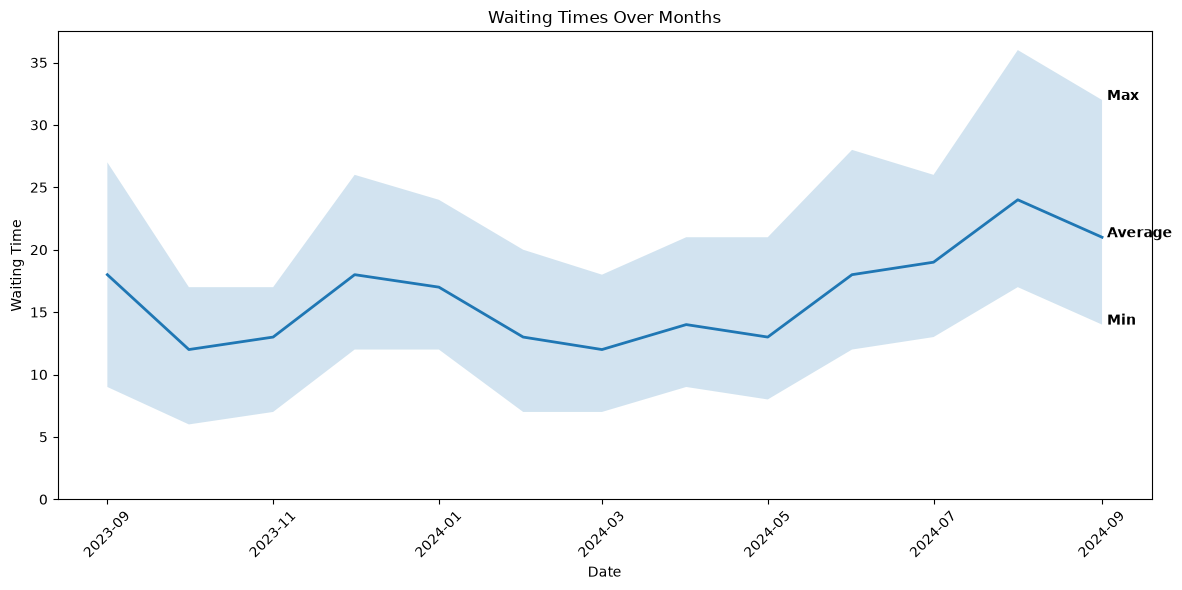

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the Excel file
df = pd.read_excel("Waiting_times.xlsx")

# Combine Year and Month into a date
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"],
    format="%Y-%b"
)

# Create the graph
plt.figure(figsize=(12, 6))

# Shaded area between minimum and maximum
plt.fill_between(
    df["Date"],
    df["Min"],
    df["Max"],
    alpha=0.2,
    label="Min–Max range"
)

# Average waiting time
plt.plot(
    df["Date"],
    df["Avg waiting time"],
    linewidth=2,
    label="Average"
)

# Add labels at the end of the lines/area
plt.text(
    df["Date"].iloc[-1],
    df["Max"].iloc[-1],
    " Max",
    fontweight="bold"
)

plt.text(
    df["Date"].iloc[-1],
    df["Avg waiting time"].iloc[-1],
    " Average",
    fontweight="bold"
)

plt.text(
    df["Date"].iloc[-1],
    df["Min"].iloc[-1],
    " Min",
    fontweight="bold"
)

# Titles and labels
plt.title("Waiting Times Over Months")
plt.xlabel("Date")
plt.ylabel("Waiting Time")

# Rotate dates
plt.xticks(rotation=45)

# Set y-axis to start at 0
plt.ylim(bottom=0)

# Clean layout
plt.tight_layout()

# Show graph
plt.show()

In [8]:
import pandas as pd
import plotly.graph_objects as go

# Read the Excel file
df = pd.read_excel("Waiting_times.xlsx")

# Create a proper date column
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"],
    format="%Y-%b"
)

# Create interactive figure
fig = go.Figure()

# Maximum waiting time
fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Max"],
    mode="lines",
    line=dict(width=0),
    name="Maximum",
    hovertemplate="Maximum: %{y}<extra></extra>"
))

# Minimum waiting time + shaded range
fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Min"],
    mode="lines",
    fill="tonexty",
    name="Min–Max range",
    hovertemplate="Minimum: %{y}<extra></extra>"
))

# Average waiting time
fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Avg waiting time"],
    mode="lines+markers",
    name="Average",
    line=dict(width=3),
    hovertemplate=(
        "<b>%{x|%B %Y}</b><br>"
        "Average waiting time: %{y}"
        "<extra></extra>"
    )
))

# Storytelling title and layout
fig.update_layout(
    title={
        "text": (
            "<b>Waiting Times Climbed Sharply in Summer 2024, "
            "Peaking in August</b>"
            "<br><sup>Average waiting time fell early in 2024 "
            "before rising substantially from May onward</sup>"
        ),
        "x": 0.05,
        "xanchor": "left"
    },

    xaxis_title="Month",
    yaxis_title="Waiting Time",

    hovermode="x unified",

    template="plotly_white",

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),

    margin=dict(t=130)
)

# Make the x-axis easier to read
fig.update_xaxes(
    tickformat="%b %Y"
)

fig.show()

In [9]:
import pandas as pd
import plotly.graph_objects as go

# Read the Excel file
df = pd.read_excel("Waiting_times.xlsx")

# Create a proper date column
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"],
    format="%Y-%b"
)

# Create interactive figure
fig = go.Figure()

# Maximum waiting time
fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Max"],
    mode="lines",
    line=dict(width=0),
    name="Maximum",
    hovertemplate="Maximum: %{y}<extra></extra>"
))

# Minimum waiting time + GREY shaded area
fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Min"],
    mode="lines",
    line=dict(width=0),
    fill="tonexty",
    fillcolor="rgba(150, 150, 150, 0.35)",
    name="Min–Max range",
    hovertemplate="Minimum: %{y}<extra></extra>"
))

# Average waiting time
fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Avg waiting time"],
    mode="lines+markers",
    name="Average",
    line=dict(
        color="blue",
        width=3
    ),
    marker=dict(
        color="blue",
        size=7
    ),
    hovertemplate=(
        "<b>%{x|%B %Y}</b><br>"
        "Average waiting time: %{y}"
        "<extra></extra>"
    )
))

# Title and layout
fig.update_layout(
    title={
        "text": (
            "<b>Waiting Times Climbed Sharply in Summer 2024, "
            "Peaking in August</b>"
            "<br><sup>Average waiting time fell early in 2024 "
            "before rising substantially from May onward</sup>"
        ),
        "x": 0.05,
        "xanchor": "left"
    },

    xaxis_title="Month",
    yaxis_title="Waiting Time",

    hovermode="x unified",
    template="plotly_white",

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),

    margin=dict(t=130)
)

# Remove gridlines
fig.update_xaxes(
    showgrid=False,
    tickformat="%b %Y"
)

fig.update_yaxes(
    showgrid=False,
    rangemode="tozero"
)

fig.show()

In [1]:
import pandas as pd
import plotly.graph_objects as go

# Data inlezen
df = pd.read_excel("Waiting_times.xlsx")

# Datum maken
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"],
    format="%Y-%b"
)

# Figuur maken
fig = go.Figure()

# Grijze Min-Max band (blijft zichtbaar)
fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Max"],
    mode="lines",
    line=dict(width=0),
    hoverinfo="skip",
    showlegend=False
))

fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Min"],
    mode="lines",
    line=dict(width=0),
    fill="tonexty",
    fillcolor="rgba(150,150,150,0.30)",
    name="Min–Max range",
    hoverinfo="skip"
))

# Gemiddelde lijn - begint alleen bij het eerste punt
fig.add_trace(go.Scatter(
    x=df["Date"].iloc[:1],
    y=df["Avg waiting time"].iloc[:1],
    mode="lines+markers",
    name="Average",
    line=dict(
        color="blue",
        width=3
    ),
    marker=dict(
        color="blue",
        size=8
    ),
    hovertemplate=(
        "<b>%{x|%B %Y}</b><br>"
        "Average waiting time: %{y} min"
        "<extra></extra>"
    )
))

# Animatieframes maken
frames = []

for i in range(1, len(df) + 1):
    frames.append(
        go.Frame(
            data=[
                go.Scatter(
                    x=df["Date"].iloc[:i],
                    y=df["Avg waiting time"].iloc[:i]
                )
            ],
            traces=[2],
            name=str(i)
        )
    )

fig.frames = frames

# Layout
fig.update_layout(

    title={
        "text": (
            "<b>Waiting Times Climbed Sharply in Summer 2024, "
            "Peaking in August</b>"
            "<br><sup>Average waiting time fell early in 2024 "
            "before rising substantially from May onward</sup>"
        ),
        "x": 0.05,
        "xanchor": "left"
    },

    xaxis_title="Month",
    yaxis_title="Waiting Time (minutes)",

    template="plotly_white",

    # Play button
    updatemenus=[
        dict(
            type="buttons",
            showactive=False,
            x=0.05,
            y=-0.18,

            buttons=[
                dict(
                    label="▶ Play",
                    method="animate",
                    args=[
                        None,
                        {
                            "frame": {
                                "duration": 500,
                                "redraw": False
                            },
                            "transition": {
                                "duration": 400
                            },
                            "fromcurrent": True,
                            "mode": "immediate"
                        }
                    ]
                ),

                dict(
                    label="⏸ Pause",
                    method="animate",
                    args=[
                        [None],
                        {
                            "frame": {
                                "duration": 0,
                                "redraw": False
                            },
                            "mode": "immediate"
                        }
                    ]
                )
            ]
        )
    ],

    margin=dict(
        t=130,
        b=100
    )
)

# Geen gridlines
fig.update_xaxes(
    showgrid=False,
    tickformat="%b %Y",
    range=[
        df["Date"].min(),
        df["Date"].max()
    ]
)

fig.update_yaxes(
    showgrid=False,
    range=[0, 40]
)

fig.show()

In [2]:
import pandas as pd
import plotly.graph_objects as go

# Data inlezen
df = pd.read_excel("Waiting_times.xlsx")

# Datum maken
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"],
    format="%Y-%b"
)

# Figuur maken
fig = go.Figure()

# Grijze Min-Max band (blijft zichtbaar)
fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Max"],
    mode="lines",
    line=dict(width=0),
    hoverinfo="skip",
    showlegend=False
))

fig.add_trace(go.Scatter(
    x=df["Date"],
    y=df["Min"],
    mode="lines",
    line=dict(width=0),
    fill="tonexty",
    fillcolor="rgba(150,150,150,0.30)",
    name="Min–Max range",
    hoverinfo="skip"
))

# Gemiddelde lijn - begint alleen bij het eerste punt
fig.add_trace(go.Scatter(
    x=df["Date"].iloc[:1],
    y=df["Avg waiting time"].iloc[:1],
    mode="lines+markers",
    name="Average",
    line=dict(
        color="blue",
        width=3
    ),
    marker=dict(
        color="blue",
        size=8
    ),
    hovertemplate=(
        "<b>%{x|%B %Y}</b><br>"
        "Average waiting time: %{y} min"
        "<extra></extra>"
    )
))

# Animatieframes maken
frames = []

for i in range(1, len(df) + 1):
    frames.append(
        go.Frame(
            data=[
                go.Scatter(
                    x=df["Date"].iloc[:i],
                    y=df["Avg waiting time"].iloc[:i]
                )
            ],
            traces=[2],
            name=str(i)
        )
    )

fig.frames = frames

# Layout
fig.update_layout(

    title={
        "text": (
            "<b>Waiting Times Climbed Sharply in Summer 2024, "
            "Peaking in August</b>"
            "<br><sup>Average waiting time fell early in 2024 "
            "before rising substantially from May onward</sup>"
        ),
        "x": 0.05,
        "xanchor": "left"
    },

    xaxis_title="Month",
    yaxis_title="Waiting Time (minutes)",

    template="plotly_white",

    # Play button
    updatemenus=[
        dict(
            type="buttons",
            showactive=False,
            x=0.05,
            y=-0.18,

            buttons=[
                dict(
                    label="▶ Play",
                    method="animate",
                    args=[
                        None,
                        {
                            "frame": {
                                "duration": 500,
                                "redraw": False
                            },
                            "transition": {
                                "duration": 400
                            },
                            "fromcurrent": True,
                            "mode": "immediate"
                        }
                    ]
                ),

                dict(
                    label="⏸ Pause",
                    method="animate",
                    args=[
                        [None],
                        {
                            "frame": {
                                "duration": 0,
                                "redraw": False
                            },
                            "mode": "immediate"
                        }
                    ]
                )
            ]
        )
    ],

    margin=dict(
        t=130,
        b=100
    )
)

# Geen gridlines
fig.update_xaxes(
    showgrid=False,
    tickformat="%b %Y",
    range=[
        df["Date"].min(),
        df["Date"].max()
    ]
)

fig.update_yaxes(
    showgrid=False,
    range=[0, 40]
)

fig.show()

***based on the data i uploaded (waiting times at the airport) can you create a visual for me using the best practise and principles as difined by cole nussbaumer knaflic in her book storytelling with data? make clear which choises are made and what principles the choises ahead. write a code***

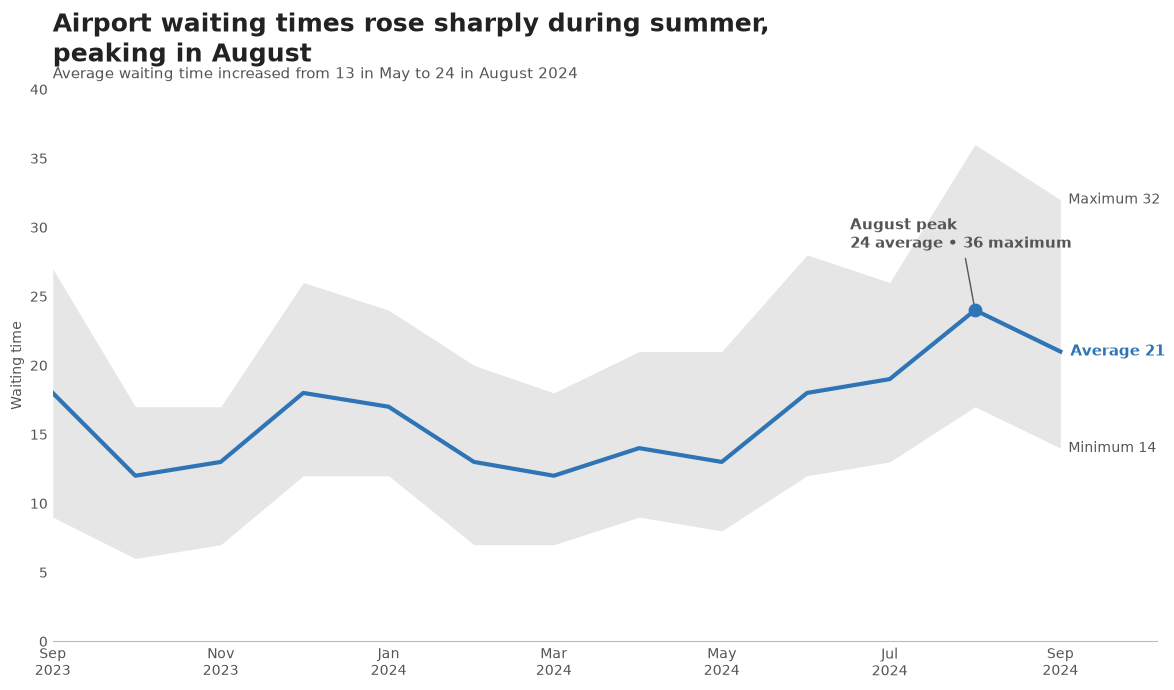

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------------
# 1. LOAD AND PREPARE THE DATA
# ---------------------------------------------------------

df = pd.read_excel("Waiting_times.xlsx")

# Combine year and month into a real date
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"],
    format="%Y-%b"
)

# ---------------------------------------------------------
# 2. SET UP THE VISUAL
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

# Colors
BLUE = "#2F75B5"       # emphasis
DARK_GREY = "#555555"  # text
LIGHT_GREY = "#D9D9D9" # contextual range


# ---------------------------------------------------------
# 3. SHOW MIN–MAX AS CONTEXT
# ---------------------------------------------------------

# The range is deliberately grey and subtle.
# It provides context without competing with the average.

ax.fill_between(
    df["Date"],
    df["Min"],
    df["Max"],
    color=LIGHT_GREY,
    alpha=0.65,
    linewidth=0
)


# ---------------------------------------------------------
# 4. EMPHASIZE THE AVERAGE
# ---------------------------------------------------------

ax.plot(
    df["Date"],
    df["Avg waiting time"],
    color=BLUE,
    linewidth=3
)


# ---------------------------------------------------------
# 5. HIGHLIGHT THE PEAK
# ---------------------------------------------------------

peak_idx = df["Avg waiting time"].idxmax()

peak_date = df.loc[peak_idx, "Date"]
peak_avg = df.loc[peak_idx, "Avg waiting time"]

ax.scatter(
    peak_date,
    peak_avg,
    color=BLUE,
    s=80,
    zorder=5
)

# Annotation tells the audience why this point matters
ax.annotate(
    "August peak\n24 average • 36 maximum",
    xy=(peak_date, peak_avg),
    xytext=(-90, 45),
    textcoords="offset points",
    fontsize=11,
    color=DARK_GREY,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-",
        color=DARK_GREY,
        linewidth=1
    )
)


# ---------------------------------------------------------
# 6. DIRECTLY LABEL THE DATA
# ---------------------------------------------------------

last = df.iloc[-1]

# Average
ax.text(
    last["Date"],
    last["Avg waiting time"],
    "  Average 21",
    color=BLUE,
    fontsize=11,
    fontweight="bold",
    va="center"
)

# Maximum
ax.text(
    last["Date"],
    last["Max"],
    "  Maximum 32",
    color=DARK_GREY,
    fontsize=10,
    va="center"
)

# Minimum
ax.text(
    last["Date"],
    last["Min"],
    "  Minimum 14",
    color=DARK_GREY,
    fontsize=10,
    va="center"
)


# ---------------------------------------------------------
# 7. STORYTELLING TITLE
# ---------------------------------------------------------

ax.set_title(
    "Airport waiting times rose sharply during summer,\n"
    "peaking in August",
    loc="left",
    fontsize=18,
    fontweight="bold",
    color="#222222",
    pad=20
)

# Subtitle
ax.text(
    0,
    1.02,
    "Average waiting time increased from 13 in May to 24 in August 2024",
    transform=ax.transAxes,
    fontsize=11,
    color=DARK_GREY
)


# ---------------------------------------------------------
# 8. DECLUTTER
# ---------------------------------------------------------

# Remove gridlines
ax.grid(False)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Keep bottom axis subtle
ax.spines["bottom"].set_color("#BBBBBB")

# Remove y-axis tick marks
ax.tick_params(
    axis="y",
    length=0,
    colors=DARK_GREY
)

ax.tick_params(
    axis="x",
    length=0,
    colors=DARK_GREY
)

# No legend needed because the chart is directly labelled
# No generic x-axis title needed
ax.set_xlabel("")

ax.set_ylabel(
    "Waiting time",
    fontsize=10,
    color=DARK_GREY
)


# ---------------------------------------------------------
# 9. FORMAT DATES
# ---------------------------------------------------------

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b\n%Y")
)

# Give direct labels some room on the right
ax.set_xlim(
    df["Date"].min(),
    df["Date"].max() + pd.Timedelta(days=35)
)

ax.set_ylim(0, 40)


# ---------------------------------------------------------
# 10. FINAL FORMATTING
# ---------------------------------------------------------

plt.tight_layout()

plt.show()

****Exercise 2****

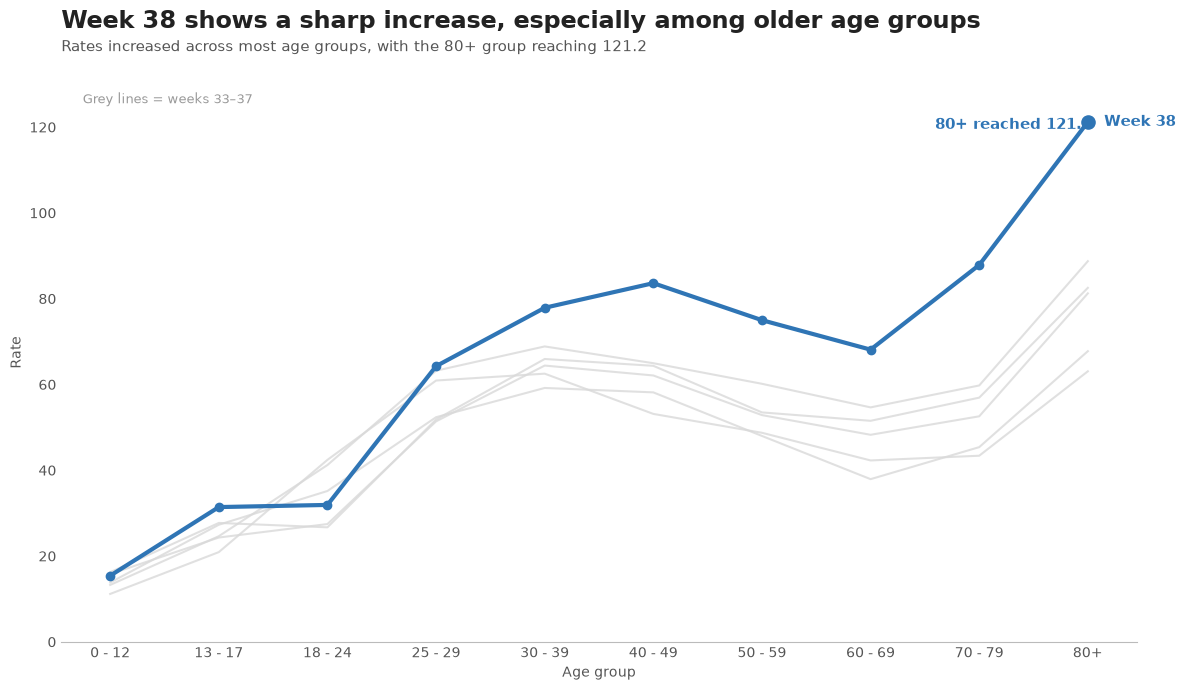

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# 1. LOAD THE DATA
# ---------------------------------------------------------

df = pd.read_excel("Week 4 Exercise 2 - RIVM data.xlsx")

# Age groups
age_groups = df["Age group"]

# Weeks that provide historical context
previous_weeks = ["wk 33", "wk 34", "wk 35", "wk 36", "wk 37"]

# Week we want to emphasize
current_week = "wk 38"


# ---------------------------------------------------------
# 2. COLORS
# ---------------------------------------------------------

# Grey = context
LIGHT_GREY = "#D9D9D9"
DARK_GREY = "#555555"

# Blue = focus / attention
BLUE = "#2F75B5"


# ---------------------------------------------------------
# 3. CREATE THE FIGURE
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(age_groups))


# ---------------------------------------------------------
# 4. SHOW WEEKS 33–37 AS CONTEXT
# ---------------------------------------------------------

# Previous weeks are deliberately light grey.
# They provide context without competing for attention.

for week in previous_weeks:
    ax.plot(
        x,
        df[week],
        color=LIGHT_GREY,
        linewidth=1.5,
        alpha=0.8
    )


# ---------------------------------------------------------
# 5. EMPHASIZE WEEK 38
# ---------------------------------------------------------

ax.plot(
    x,
    df[current_week],
    color=BLUE,
    linewidth=3,
    marker="o",
    markersize=6
)


# ---------------------------------------------------------
# 6. HIGHLIGHT THE 80+ VALUE
# ---------------------------------------------------------

last_x = x[-1]
last_value = df[current_week].iloc[-1]

ax.scatter(
    last_x,
    last_value,
    color=BLUE,
    s=90,
    zorder=5
)

ax.annotate(
    "80+ reached 121.2",
    xy=(last_x, last_value),
    xytext=(-110, -5),
    textcoords="offset points",
    fontsize=11,
    fontweight="bold",
    color=BLUE
)


# ---------------------------------------------------------
# 7. DIRECTLY LABEL WEEK 38
# ---------------------------------------------------------

ax.text(
    last_x + 0.15,
    last_value,
    "Week 38",
    color=BLUE,
    fontsize=11,
    fontweight="bold",
    va="center"
)


# ---------------------------------------------------------
# 8. STORYTELLING TITLE
# ---------------------------------------------------------

ax.set_title(
    "Week 38 shows a sharp increase, especially among older age groups",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#222222",
    pad=25
)

# Subtitle
ax.text(
    0,
    1.02,
    "Rates increased across most age groups, with the 80+ group reaching 121.2",
    transform=ax.transAxes,
    fontsize=11,
    color=DARK_GREY
)


# ---------------------------------------------------------
# 9. FORMAT THE X-AXIS
# ---------------------------------------------------------

ax.set_xticks(x)
ax.set_xticklabels(age_groups)

ax.set_xlabel("Age group", color=DARK_GREY)
ax.set_ylabel("Rate", color=DARK_GREY)


# ---------------------------------------------------------
# 10. DECLUTTER
# ---------------------------------------------------------

# Remove gridlines
ax.grid(False)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Keep bottom axis subtle
ax.spines["bottom"].set_color("#BBBBBB")

# Remove tick marks
ax.tick_params(
    axis="both",
    length=0,
    colors=DARK_GREY
)

# No legend:
# direct labeling and visual hierarchy make it unnecessary.


# ---------------------------------------------------------
# 11. ADD A SMALL CONTEXT LABEL
# ---------------------------------------------------------

ax.text(
    0.02,
    0.93,
    "Grey lines = weeks 33–37",
    transform=ax.transAxes,
    fontsize=9,
    color="#999999"
)


# ---------------------------------------------------------
# 12. FINAL FORMATTING
# ---------------------------------------------------------

ax.set_ylim(0, 135)

plt.tight_layout()

plt.show()